DATASET OVERVIEW
Total samples: 4,237,907
Total subjects: 36
Gesture classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]

Total recording sessions: 72
Sessions per subject:
series
2    36
Name: count, dtype: int64

Total gesture blocks: 1812

FEATURE EXTRACTION
Feature DataFrame shape: (1812, 44)
Total strokes: 1812


,MAV_ch1,RMS_ch1,NE_ch1,MAX_ch1,MAV_ch2,RMS_ch2,NE_ch2,MAX_ch2,MAV_ch3,RMS_ch3,...,series,class,NMAX_ch1,NMAX_ch2,NMAX_ch3,NMAX_ch4,NMAX_ch5,NMAX_ch6,NMAX_ch7,NMAX_ch8
0,0.000011,0.000015,0.100636,0.000017,0.000018,0.000025,0.164699,0.000029,0.000020,0.000027,...,1,0,0.100351,0.144950,0.172920,0.162486,0.054070,0.060772,0.097182,0.080955
1,0.000012,0.000016,0.104275,0.000016,0.000019,0.000025,0.171418,0.000025,0.000021,0.000028,...,1,1,0.092468,0.123766,0.167107,0.097560,0.063458,0.062441,0.082986,0.081992
2,0.000116,0.000202,0.117101,0.000310,0.000069,0.000107,0.070264,0.000152,0.000096,0.000144,...,1,0,1.824397,0.762614,1.152342,1.030683,0.916100,1.690950,3.968419,2.685257
3,0.000189,0.000254,0.153566,0.000360,0.000105,0.000138,0.085116,0.000147,0.000171,0.000221,...,1,2,2.113459,0.735396,1.566345,1.049156,0.644400,1.026053,2.538136,1.478215
4,0.000104,0.000212,0.131155,0.000455,0.000099,0.000216,0.124560,0.000474,0.000088,0.000189,...,1,0,2.671922,2.373072,2.728364,1.980841,1.473592,1.980039,2.867484,3.079687



FILTERED DATASET
Remaining classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Remaining strokes: 864

Strokes per gesture:
class
1    144
2    144
3    144
4    144
5    144
6    144
Name: count, dtype: int64

Input shape: (864, 8)
Target shape: (864,)
Number of subjects: 36

TRAIN/TEST SPLIT
Training subjects: 29
Testing subjects:  7

Training strokes: 696
Testing strokes:  168

Training percentage: 80.56%
Testing percentage:  19.44%

Training subject IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 15, 16, 18, 19, 20, 21, 23, 24, 25, 26, 28, 29, 30, 33, 34, 35]
Testing subject IDs: [14, 17, 22, 27, 31, 32, 36]

Subject overlap: None

Class distribution:


,Training,Testing
class,,
1,116,28
2,116,28
3,116,28
4,116,28
5,116,28
6,116,28



Random Forest training completed.

RANDOM FOREST PERFORMANCE
Training accuracy: 0.9511 (95.11%)
Testing accuracy:  0.7917 (79.17%)

Classification Report (Test Set):
              precision    recall  f1-score   support

           1       0.64      0.89      0.75        28
           2       0.89      0.89      0.89        28
           3       0.62      0.71      0.67        28
           4       0.96      0.86      0.91        28
           5       1.00      0.71      0.83        28
           6       0.79      0.68      0.73        28

    accuracy                           0.79       168
   macro avg       0.82      0.79      0.80       168
weighted avg       0.82      0.79      0.80       168



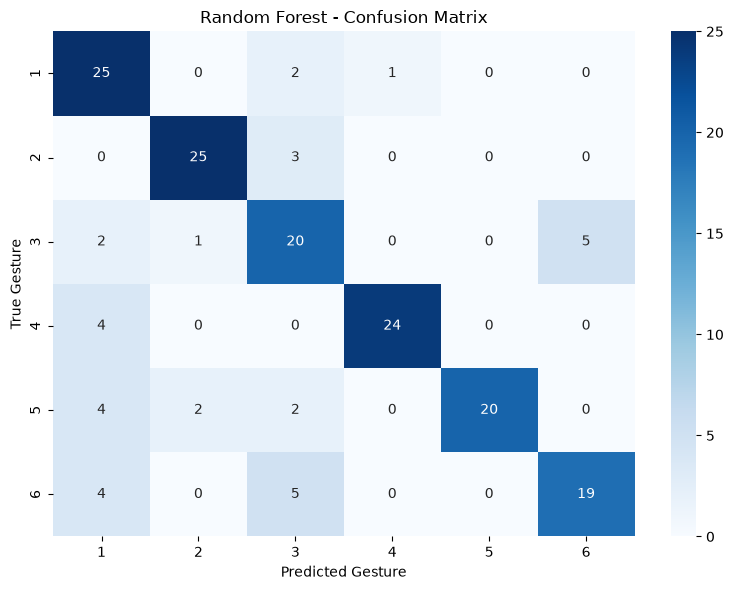


Feature Importance:


,Importance
NE_ch7,0.141995
NE_ch8,0.131859
NE_ch1,0.130130
NE_ch5,0.129933
NE_ch2,0.124804
NE_ch4,0.121298
NE_ch3,0.119822
NE_ch6,0.100159


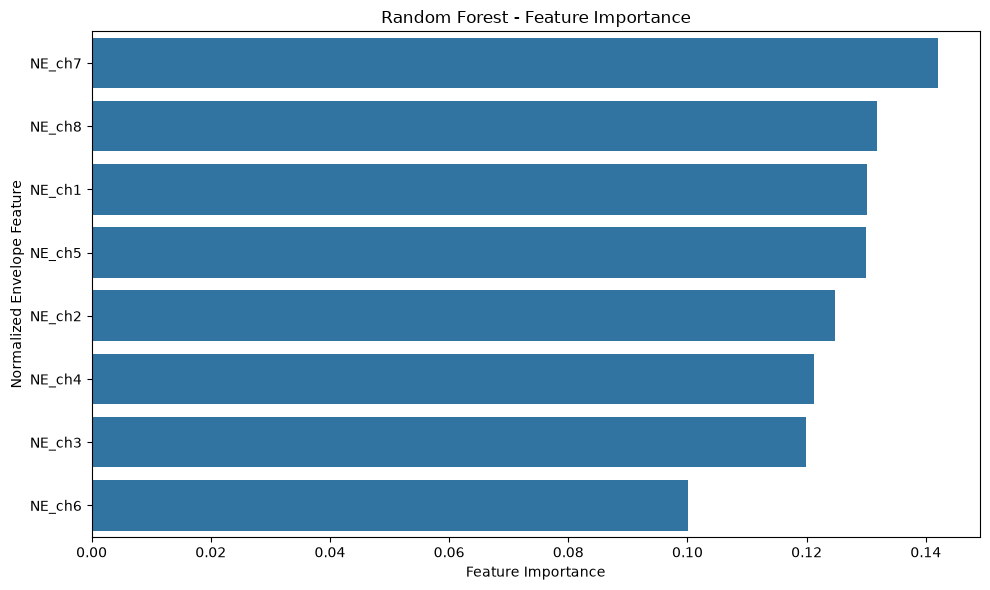

Training accuracy per fold: [0.943 0.948 0.945 0.943 0.955]
Test accuracy per fold: [0.807 0.786 0.893 0.815 0.643]

Mean training accuracy: 0.947
Mean test accuracy: 0.789
Test accuracy SD: 0.081


In [11]:
# ============================================================
# EMG HAND GESTURE CLASSIFICATION - RANDOM FOREST
# ============================================================

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import butter, filtfilt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)


# ============================================================
# 2. LOAD DATASET
# ============================================================

data = pd.read_csv("Project_Data_EE4C12_S&S_EMG.csv")

channels = [f"channel{i}" for i in range(1, 9)]

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print(f"Total samples: {len(data):,}")
print(f"Total subjects: {data['label'].nunique()}")
print(f"Gesture classes: {sorted(data['class'].unique())}")


# ============================================================
# 3. IDENTIFY RECORDING SESSIONS
# ============================================================

# Identify when time resets for each subject
data["new_series"] = (
    data.groupby("label")["time"]
        .diff()
        .fillna(1)
        <= 0
)

# First row of each subject starts a new series
data["new_series"] = (
    data["new_series"]
    | data.groupby("label").cumcount().eq(0)
)

# Assign series number within each subject
data["series"] = (
    data.groupby("label")["new_series"]
        .cumsum()
        .astype(int)
)

data.drop(columns="new_series", inplace=True)

print("\nTotal recording sessions:",
      data.groupby(["label", "series"]).ngroups)

print("Sessions per subject:")
print(data.groupby("label")["series"].nunique().value_counts())


# ============================================================
# 4. IDENTIFY INDIVIDUAL GESTURE STROKES
# ============================================================

# A new stroke begins when:
# - The gesture class changes
# - The recording session changes
# - The subject changes

data["new_gesture"] = (
    data["class"].ne(data["class"].shift())
    | data["series"].ne(data["series"].shift())
    | data["label"].ne(data["label"].shift())
)

data["gesture_block"] = data["new_gesture"].cumsum()

print("\nTotal gesture blocks:",
      data["gesture_block"].nunique())


# ============================================================
# 5. FEATURE EXTRACTION
# ============================================================

feature_rows = []

# Loop through each gesture stroke
for _, group in data.groupby("gesture_block", sort=False):

    stroke = group[channels].to_numpy(dtype=float)

    # Rectify EMG signal
    rectified = np.abs(stroke)
    fs = 1000
    cutoff = 3
    order = 4

    # Design low-pass Butterworth filter
    b, a = butter(
        order,
        cutoff / (fs / 2),
        btype="low"
    )
    rectified = filtfilt(b, a, rectified, axis=0)

    # Maximum amplitude of the filtered EMG envelope
    max_values = np.max(rectified, axis=0)

    # Mean Absolute Value
    mav = np.mean(rectified, axis=0)

    # Root Mean Square
    rms = np.sqrt(np.mean(stroke**2, axis=0))

    # Total envelope magnitude
    total_envelope = np.sum(mav)

    # Normalized envelope
    normalized_envelope = mav / (total_envelope + 1e-10)

    # Log total envelope
    log_total_envelope = np.log(total_envelope + 1e-10)

    # Store features
    features = {}

    for ch in range(8):

        features[f"MAV_ch{ch+1}"] = mav[ch]
        features[f"RMS_ch{ch+1}"] = rms[ch]
        features[f"NE_ch{ch+1}"] = normalized_envelope[ch]
        features[f"MAX_ch{ch+1}"] = max_values[ch]

    features["Log_Total_Envelope"] = log_total_envelope

    # Store subject, session and gesture class
    features["label"] = group["label"].iloc[0]
    features["series"] = group["series"].iloc[0]
    features["class"] = group["class"].iloc[0]

    feature_rows.append(features)

# Create feature DataFrame
features_df = pd.DataFrame(feature_rows)

max_cols = [f"MAX_ch{i}" for i in range(1, 9)]

# Step 1: Calculate mean MAX for each subject, session,
# gesture class and channel.
class_means = (
    features_df
    .groupby(["label", "series", "class"])[max_cols]
    .mean()
    .reset_index()
)

# Step 2: Calculate class-balanced reference values
# for each subject, session and channel.
balanced_means = (
    class_means
    .groupby(["label", "series"])[max_cols]
    .mean()
)

# Step 3: Match reference values to each gesture block.
reference = features_df.set_index(["label", "series"]).index

balanced_values = (
    balanced_means
    .reindex(reference)
    .to_numpy()
)

# Step 4: Normalize MAX using the reference values.
for i, col in enumerate(max_cols):

    features_df[f"NMAX_ch{i+1}"] = (
        features_df[col] /
        (balanced_values[:, i] + 1e-10)
    )

print("\n" + "=" * 60)
print("FEATURE EXTRACTION")
print("=" * 60)

print("Feature DataFrame shape:", features_df.shape)
print("Total strokes:", len(features_df))

display(features_df.head())


# ============================================================
# 6. FILTER GESTURE CLASSES
# ============================================================

# Exclude classes 0 and 7
df_model = features_df[
    ~features_df["class"].isin([0, 7])
].copy()

print("\n" + "=" * 60)
print("FILTERED DATASET")
print("=" * 60)

print("Remaining classes:",
      sorted(df_model["class"].unique()))

print("Remaining strokes:", len(df_model))

print("\nStrokes per gesture:")
print(df_model["class"].value_counts().sort_index())


# ============================================================
# 7. SELECT INPUT FEATURES AND TARGET
# ============================================================

# Use 8 normalized envelope features
feature_cols = [f"NE_ch{i}" for i in range(1, 9)]

X = df_model[feature_cols]
y = df_model["class"]

# Group by subject
groups = df_model["label"]

print("\nInput shape:", X.shape)
print("Target shape:", y.shape)
print("Number of subjects:", groups.nunique())

assert groups.nunique() == 36, (
    "Expected 36 subjects. Check the subject labels."
)

assert not X.isna().any().any(), (
    "Missing feature values detected."
)

assert np.isfinite(X.to_numpy()).all(), (
    "Non-finite feature values detected."
)


# ============================================================
# 8. SUBJECT-BASED TRAIN/TEST SPLIT (80/20)
# ============================================================

# 29 subjects for training, 7 for testing
# Both sessions from each subject stay together

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=7,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

train_subjects = set(groups.iloc[train_idx])
test_subjects = set(groups.iloc[test_idx])

print("\n" + "=" * 60)
print("TRAIN/TEST SPLIT")
print("=" * 60)

print(f"Training subjects: {len(train_subjects)}")
print(f"Testing subjects:  {len(test_subjects)}")

print(f"\nTraining strokes: {len(X_train)}")
print(f"Testing strokes:  {len(X_test)}")

print(f"\nTraining percentage: {len(X_train)/len(X)*100:.2f}%")
print(f"Testing percentage:  {len(X_test)/len(X)*100:.2f}%")

print("\nTraining subject IDs:", sorted(train_subjects))
print("Testing subject IDs:", sorted(test_subjects))

# Verify no subject overlap
assert train_subjects.isdisjoint(test_subjects), (
    "ERROR: Subjects overlap between training and testing!"
)

print("\nSubject overlap: None")

# Verify all gesture classes appear in both sets
expected_classes = set(y.unique())

assert set(y_train.unique()) == expected_classes, (
    "Some gesture classes are missing from training."
)

assert set(y_test.unique()) == expected_classes, (
    "Some gesture classes are missing from testing."
)

# Class distribution
class_distribution = pd.DataFrame({
    "Training": y_train.value_counts(),
    "Testing": y_test.value_counts()
}).fillna(0).astype(int).sort_index()

print("\nClass distribution:")
display(class_distribution)


# ============================================================
# 9. TRAIN REGULARIZED RANDOM FOREST
# ============================================================

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("\nRandom Forest training completed.")


# ============================================================
# 10. MODEL PREDICTIONS
# ============================================================

y_train_pred = rf_model.predict(X_train)
y_test_pred = rf_model.predict(X_test)


# ============================================================
# 11. MODEL EVALUATION
# ============================================================

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("\n" + "=" * 60)
print("RANDOM FOREST PERFORMANCE")
print("=" * 60)

print(f"Training accuracy: {train_accuracy:.4f} "
      f"({train_accuracy*100:.2f}%)")

print(f"Testing accuracy:  {test_accuracy:.4f} "
      f"({test_accuracy*100:.2f}%)")

print("\nClassification Report (Test Set):")
print(classification_report(
    y_test,
    y_test_pred,
    zero_division=0
))


# ============================================================
# 12. CONFUSION MATRIX
# ============================================================

classes = sorted(y.unique())

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=classes
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()


# ============================================================
# 13. FEATURE IMPORTANCE
# ============================================================

importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_cols
).sort_values(ascending=False)

print("\nFeature Importance:")
display(importance.to_frame("Importance"))

plt.figure(figsize=(10, 6))

sns.barplot(
    x=importance.values,
    y=importance.index
)

plt.title("Random Forest - Feature Importance")
plt.xlabel("Feature Importance")
plt.ylabel("Normalized Envelope Feature")

plt.tight_layout()
plt.show()





# ============================================================
# 14. GROUP CROSS-VALIDATION
# ============================================================

from sklearn.model_selection import GroupKFold, cross_validate

cv_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

cv = GroupKFold(n_splits=5)

cv_results = cross_validate(
    cv_model,
    X,
    y,
    groups=groups,
    cv=cv,
    scoring="accuracy",
    return_train_score=True,
    n_jobs=1
)

print("Training accuracy per fold:",
      np.round(cv_results["train_score"], 3))

print("Test accuracy per fold:",
      np.round(cv_results["test_score"], 3))

print(f"\nMean training accuracy: "
      f"{cv_results['train_score'].mean():.3f}")

print(f"Mean test accuracy: "
      f"{cv_results['test_score'].mean():.3f}")

print(f"Test accuracy SD: "
      f"{cv_results['test_score'].std():.3f}")

In [110]:
# ============================================================
# INITIALIZE MODEL COMPARISON
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Store results from each model
model_results = {}

# Keep the original subject-based split
train_indices = X_train.index
test_indices = X_test.index

MODEL 1: NORMALIZED ENVELOPE
Training accuracy: 1.0
Testing accuracy: 0.9047619047619048

Classification Report:
              precision    recall  f1-score   support

           1       0.97      1.00      0.98        28
           2       0.75      0.86      0.80        28
           3       0.80      0.86      0.83        28
           4       1.00      1.00      1.00        28
           5       1.00      0.89      0.94        28
           6       0.96      0.82      0.88        28

    accuracy                           0.90       168
   macro avg       0.91      0.90      0.91       168
weighted avg       0.91      0.90      0.91       168



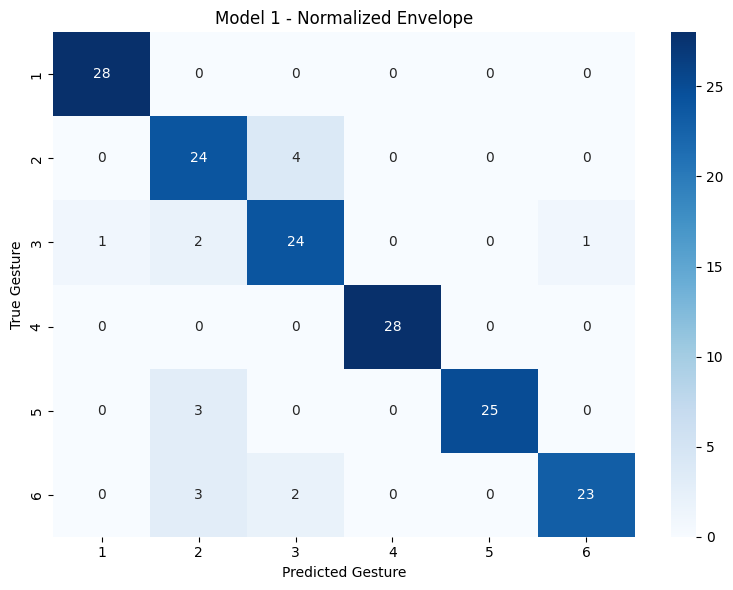

In [111]:
# ============================================================
# MODEL 1: NORMALIZED ENVELOPE
# ============================================================

features_1 = [f"NE_ch{i}" for i in range(1, 9)]

X_train_1 = df_model.loc[train_indices, features_1]
X_test_1 = df_model.loc[test_indices, features_1]

rf_1 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_1.fit(X_train_1, y_train)

y_train_pred_1 = rf_1.predict(X_train_1)
y_test_pred_1 = rf_1.predict(X_test_1)

model_results["NE"] = {
    "n_features": len(features_1),
    "train_accuracy": accuracy_score(y_train, y_train_pred_1),
    "test_accuracy": accuracy_score(y_test, y_test_pred_1),
    "f1_macro": f1_score(y_test, y_test_pred_1, average="macro")
}

print("MODEL 1: NORMALIZED ENVELOPE")
print("Training accuracy:", accuracy_score(y_train, y_train_pred_1))
print("Testing accuracy:", accuracy_score(y_test, y_test_pred_1))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_1))

plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, y_test_pred_1),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Model 1 - Normalized Envelope")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

MODEL 2: MAV
Training accuracy: 1.0
Testing accuracy: 0.8392857142857143

Classification Report:
              precision    recall  f1-score   support

           1       0.93      1.00      0.97        28
           2       0.82      0.82      0.82        28
           3       0.83      0.71      0.77        28
           4       1.00      0.82      0.90        28
           5       0.72      1.00      0.84        28
           6       0.79      0.68      0.73        28

    accuracy                           0.84       168
   macro avg       0.85      0.84      0.84       168
weighted avg       0.85      0.84      0.84       168



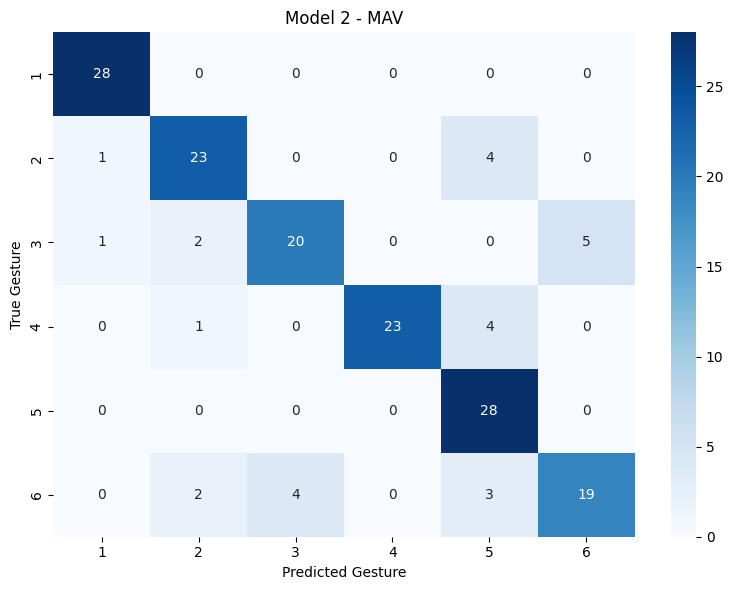

In [112]:
# ============================================================
# MODEL 2: MEAN ABSOLUTE VALUE
# ============================================================

features_2 = [f"MAV_ch{i}" for i in range(1, 9)]

X_train_2 = df_model.loc[train_indices, features_2]
X_test_2 = df_model.loc[test_indices, features_2]

rf_2 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_2.fit(X_train_2, y_train)

y_train_pred_2 = rf_2.predict(X_train_2)
y_test_pred_2 = rf_2.predict(X_test_2)

model_results["MAV"] = {
    "n_features": len(features_2),
    "train_accuracy": accuracy_score(y_train, y_train_pred_2),
    "test_accuracy": accuracy_score(y_test, y_test_pred_2),
    "f1_macro": f1_score(y_test, y_test_pred_2, average="macro")
}

print("MODEL 2: MAV")
print("Training accuracy:", accuracy_score(y_train, y_train_pred_2))
print("Testing accuracy:", accuracy_score(y_test, y_test_pred_2))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_2))

plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, y_test_pred_2),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Model 2 - MAV")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

MODEL 3: RMS
Training accuracy: 1.0
Testing accuracy: 0.8333333333333334

Classification Report:
              precision    recall  f1-score   support

           1       0.97      1.00      0.98        28
           2       0.92      0.82      0.87        28
           3       0.77      0.71      0.74        28
           4       1.00      0.79      0.88        28
           5       0.68      1.00      0.81        28
           6       0.76      0.68      0.72        28

    accuracy                           0.83       168
   macro avg       0.85      0.83      0.83       168
weighted avg       0.85      0.83      0.83       168



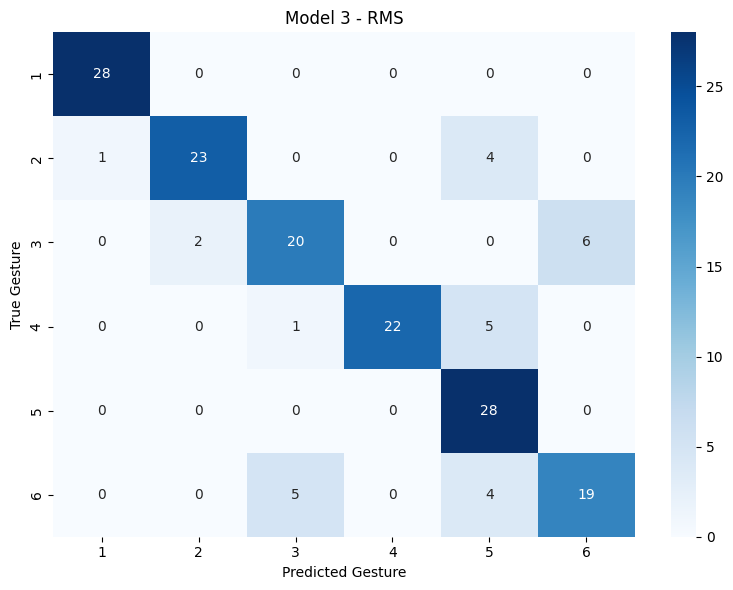

In [113]:
# ============================================================
# MODEL 3: ROOT MEAN SQUARE
# ============================================================

features_3 = [f"RMS_ch{i}" for i in range(1, 9)]

X_train_3 = df_model.loc[train_indices, features_3]
X_test_3 = df_model.loc[test_indices, features_3]

rf_3 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_3.fit(X_train_3, y_train)

y_train_pred_3 = rf_3.predict(X_train_3)
y_test_pred_3 = rf_3.predict(X_test_3)

model_results["RMS"] = {
    "n_features": len(features_3),
    "train_accuracy": accuracy_score(y_train, y_train_pred_3),
    "test_accuracy": accuracy_score(y_test, y_test_pred_3),
    "f1_macro": f1_score(y_test, y_test_pred_3, average="macro")
}

print("MODEL 3: RMS")
print("Training accuracy:", accuracy_score(y_train, y_train_pred_3))
print("Testing accuracy:", accuracy_score(y_test, y_test_pred_3))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_3))

plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, y_test_pred_3),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Model 3 - RMS")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

In [114]:
# ============================================================
# MODEL 4: NORMALIZED ENVELOPE + LOG TOTAL ENVELOPE
# ============================================================

features_4 = (
    [f"NE_ch{i}" for i in range(1, 9)]
    + ["Log_Total_Envelope"]
)

X_train_4 = df_model.loc[train_indices, features_4]
X_test_4 = df_model.loc[test_indices, features_4]

rf_4 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_4.fit(X_train_4, y_train)

y_train_pred_4 = rf_4.predict(X_train_4)
y_test_pred_4 = rf_4.predict(X_test_4)

model_results["NE + Log"] = {
    "n_features": len(features_4),
    "train_accuracy": accuracy_score(y_train, y_train_pred_4),
    "test_accuracy": accuracy_score(y_test, y_test_pred_4),
    "f1_macro": f1_score(y_test, y_test_pred_4, average="macro")
}

print("MODEL 4: NE + LOG TOTAL ENVELOPE")
print("Training accuracy:", accuracy_score(y_train, y_train_pred_4))
print("Testing accuracy:", accuracy_score(y_test, y_test_pred_4))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_4))

plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, y_test_pred_4),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Model 4 - NE + Log Total Envelope")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

KeyError: "['Log_Total_Envelope'] not in index"

MODEL 5: MAV + RMS
Training accuracy: 1.0
Testing accuracy: 0.7857142857142857

Classification Report:
              precision    recall  f1-score   support

           1       0.90      1.00      0.95        28
           2       0.62      0.89      0.74        28
           3       0.76      0.68      0.72        28
           4       1.00      0.79      0.88        28
           5       0.74      0.71      0.73        28
           6       0.78      0.64      0.71        28

    accuracy                           0.79       168
   macro avg       0.80      0.79      0.79       168
weighted avg       0.80      0.79      0.79       168



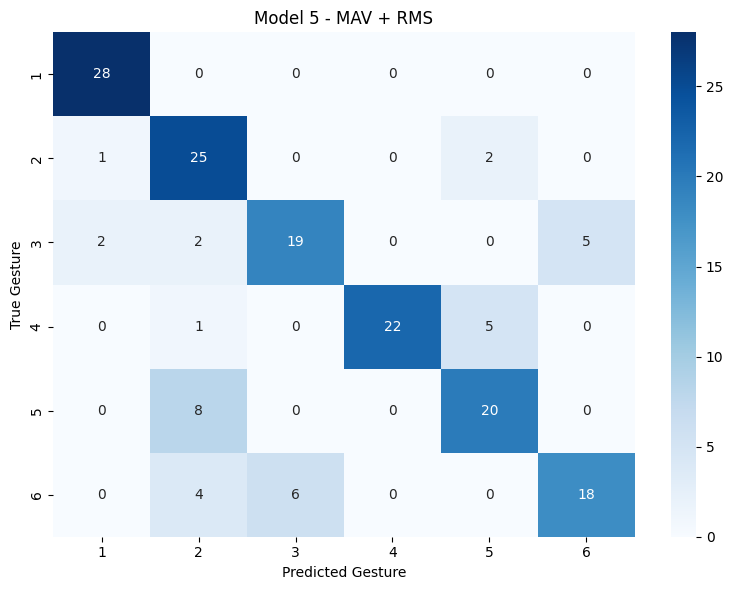

In [ ]:
# ============================================================
# MODEL 5: MAV + RMS
# ============================================================

features_5 = (
    [f"MAV_ch{i}" for i in range(1, 9)]
    + [f"RMS_ch{i}" for i in range(1, 9)]
)

X_train_5 = df_model.loc[train_indices, features_5]
X_test_5 = df_model.loc[test_indices, features_5]

rf_5 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_5.fit(X_train_5, y_train)

y_train_pred_5 = rf_5.predict(X_train_5)
y_test_pred_5 = rf_5.predict(X_test_5)

model_results["MAV + RMS"] = {
    "n_features": len(features_5),
    "train_accuracy": accuracy_score(y_train, y_train_pred_5),
    "test_accuracy": accuracy_score(y_test, y_test_pred_5),
    "f1_macro": f1_score(y_test, y_test_pred_5, average="macro")
}

print("MODEL 5: MAV + RMS")
print("Training accuracy:", accuracy_score(y_train, y_train_pred_5))
print("Testing accuracy:", accuracy_score(y_test, y_test_pred_5))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_5))

plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, y_test_pred_5),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Model 5 - MAV + RMS")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

MODEL 6: ALL FEATURES
Training accuracy: 1.0
Testing accuracy: 0.8214285714285714

Classification Report:
              precision    recall  f1-score   support

           1       0.93      1.00      0.97        28
           2       0.79      0.82      0.81        28
           3       0.83      0.71      0.77        28
           4       1.00      0.79      0.88        28
           5       0.66      0.89      0.76        28
           6       0.80      0.71      0.75        28

    accuracy                           0.82       168
   macro avg       0.84      0.82      0.82       168
weighted avg       0.84      0.82      0.82       168



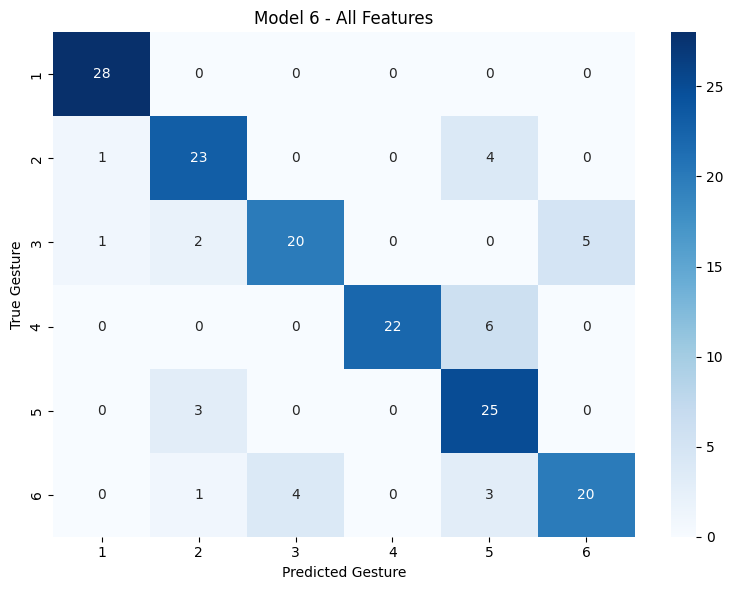

In [ ]:
# ============================================================
# MODEL 6: ALL FEATURES
# ============================================================

features_6 = (
    [f"MAV_ch{i}" for i in range(1, 9)]
    + [f"RMS_ch{i}" for i in range(1, 9)]
    + [f"NE_ch{i}" for i in range(1, 9)]
    + ["Log_Total_Envelope"]
)

X_train_6 = df_model.loc[train_indices, features_6]
X_test_6 = df_model.loc[test_indices, features_6]

rf_6 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_6.fit(X_train_6, y_train)

y_train_pred_6 = rf_6.predict(X_train_6)
y_test_pred_6 = rf_6.predict(X_test_6)

model_results["All Features"] = {
    "n_features": len(features_6),
    "train_accuracy": accuracy_score(y_train, y_train_pred_6),
    "test_accuracy": accuracy_score(y_test, y_test_pred_6),
    "f1_macro": f1_score(y_test, y_test_pred_6, average="macro")
}

print("MODEL 6: ALL FEATURES")
print("Training accuracy:", accuracy_score(y_train, y_train_pred_6))
print("Testing accuracy:", accuracy_score(y_test, y_test_pred_6))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_6))

plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, y_test_pred_6),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Model 6 - All Features")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

MODEL 7: NE + LOG TOTAL ENVELOPE + RMS
Training accuracy: 100.00%
Testing accuracy:  82.74%

Classification Report:
              precision    recall  f1-score   support

           1       0.97      1.00      0.98        28
           2       0.79      0.82      0.81        28
           3       0.84      0.75      0.79        28
           4       1.00      0.82      0.90        28
           5       0.65      0.86      0.74        28
           6       0.80      0.71      0.75        28

    accuracy                           0.83       168
   macro avg       0.84      0.83      0.83       168
weighted avg       0.84      0.83      0.83       168



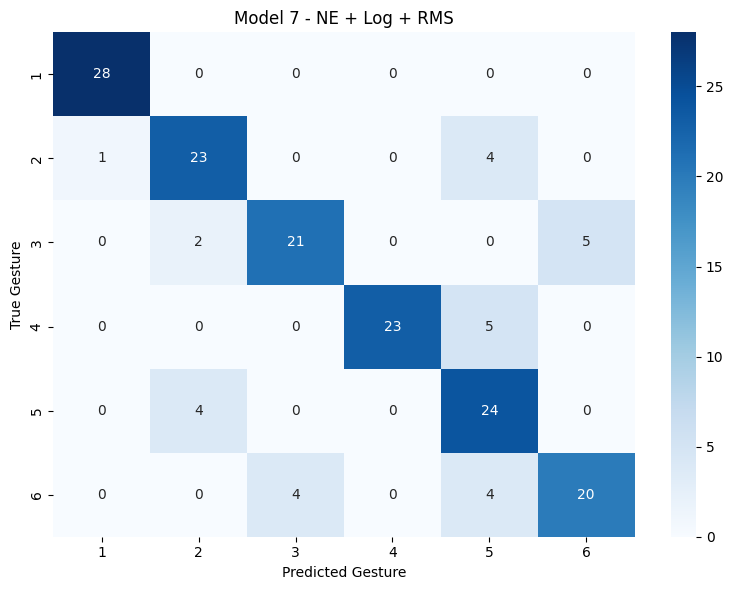

In [ ]:
# ============================================================
# MODEL 7: NORMALIZED ENVELOPE + LOG TOTAL ENVELOPE + RMS
# ============================================================

features_7 = (
    [f"NE_ch{i}" for i in range(1, 9)]
    + ["Log_Total_Envelope"]
    + [f"RMS_ch{i}" for i in range(1, 9)]
)

X_train_7 = df_model.loc[train_indices, features_7]
X_test_7 = df_model.loc[test_indices, features_7]

rf_7 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_7.fit(X_train_7, y_train)

y_train_pred_7 = rf_7.predict(X_train_7)
y_test_pred_7 = rf_7.predict(X_test_7)

model_results["NE + Log + RMS"] = {
    "n_features": len(features_7),
    "train_accuracy": accuracy_score(y_train, y_train_pred_7),
    "test_accuracy": accuracy_score(y_test, y_test_pred_7),
    "f1_macro": f1_score(y_test, y_test_pred_7, average="macro")
}

print("=" * 60)
print("MODEL 7: NE + LOG TOTAL ENVELOPE + RMS")
print("=" * 60)

print(f"Training accuracy: {accuracy_score(y_train, y_train_pred_7)*100:.2f}%")
print(f"Testing accuracy:  {accuracy_score(y_test, y_test_pred_7)*100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_7))

# Confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, y_test_pred_7),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Model 7 - NE + Log + RMS")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

RANDOM FOREST MODEL COMPARISON


,n_features,train_accuracy,test_accuracy,f1_macro
MAV,8.0,100.0,83.93,83.75
RMS,8.0,100.0,83.33,83.33
NE + Log,9.0,100.0,82.74,82.79
NE + Log + RMS,17.0,100.0,82.74,82.95
All Features,25.0,100.0,82.14,82.23
NE,8.0,100.0,79.17,79.30
MAV + RMS,16.0,100.0,78.57,78.58


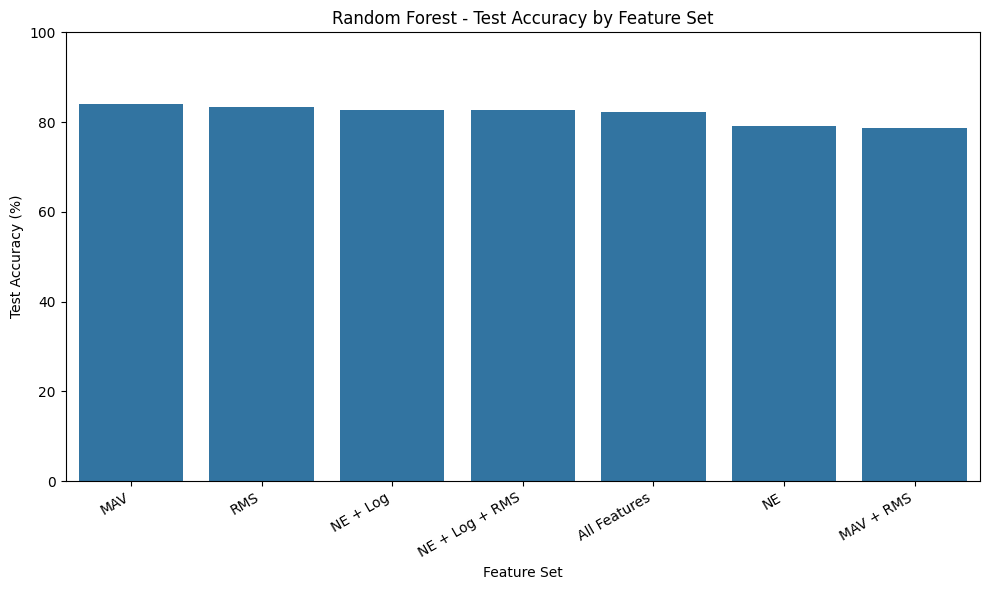

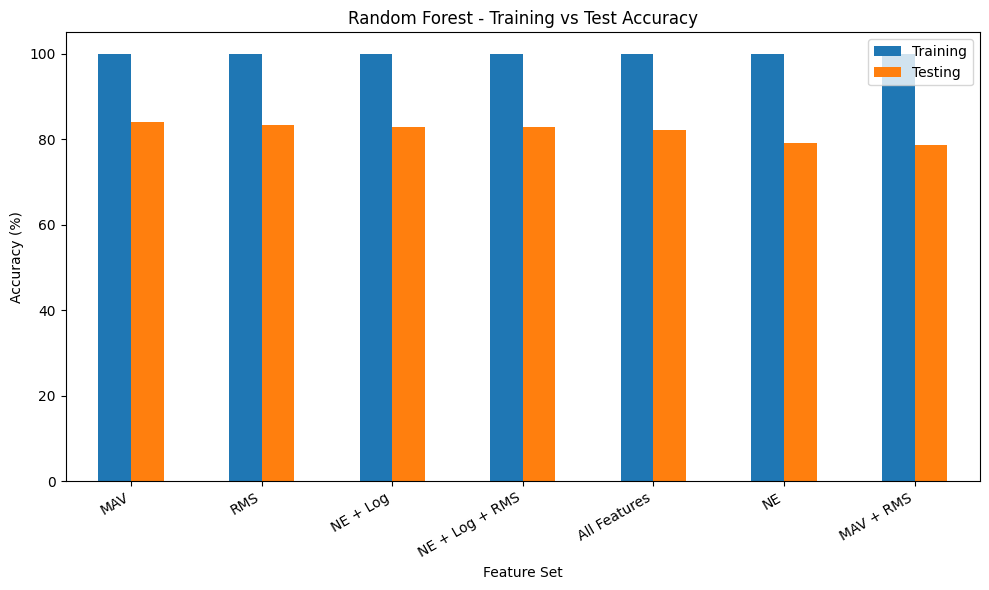

In [ ]:
# ============================================================
# RANDOM FOREST MODEL COMPARISON
# ============================================================

# Convert results dictionary into DataFrame
results_df = pd.DataFrame(model_results).T

# Convert accuracy and F1-score to percentages
results_df["train_accuracy"] *= 100
results_df["test_accuracy"] *= 100
results_df["f1_macro"] *= 100

# Sort models by test accuracy
results_df = results_df.sort_values(
    "test_accuracy",
    ascending=False
)

print("=" * 60)
print("RANDOM FOREST MODEL COMPARISON")
print("=" * 60)

display(results_df.round(2))


# ============================================================
# PLOT 1: TEST ACCURACY COMPARISON
# ============================================================

plt.figure(figsize=(10, 6))

sns.barplot(
    x=results_df.index,
    y=results_df["test_accuracy"]
)

plt.title("Random Forest - Test Accuracy by Feature Set")
plt.xlabel("Feature Set")
plt.ylabel("Test Accuracy (%)")

plt.xticks(rotation=30, ha="right")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()


# ============================================================
# PLOT 2: TRAINING VS TEST ACCURACY
# ============================================================

accuracy_comparison = results_df[
    ["train_accuracy", "test_accuracy"]
]

accuracy_comparison.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Random Forest - Training vs Test Accuracy")
plt.xlabel("Feature Set")
plt.ylabel("Accuracy (%)")

plt.xticks(rotation=30, ha="right")
plt.ylim(0, 105)
plt.legend(["Training", "Testing"])

plt.tight_layout()
plt.show()


MODEL: NE
Fold 1: Accuracy = 75.00% | F1 = 74.45%
Fold 2: Accuracy = 86.11% | F1 = 86.11%
Fold 3: Accuracy = 70.83% | F1 = 71.29%
Fold 4: Accuracy = 74.31% | F1 = 74.16%
Fold 5: Accuracy = 88.33% | F1 = 87.94%

MODEL: MAV
Fold 1: Accuracy = 80.56% | F1 = 80.64%
Fold 2: Accuracy = 84.72% | F1 = 84.44%
Fold 3: Accuracy = 76.39% | F1 = 76.23%
Fold 4: Accuracy = 82.64% | F1 = 82.74%
Fold 5: Accuracy = 96.67% | F1 = 96.65%

MODEL: RMS
Fold 1: Accuracy = 79.17% | F1 = 79.17%
Fold 2: Accuracy = 84.72% | F1 = 84.34%
Fold 3: Accuracy = 80.56% | F1 = 80.40%
Fold 4: Accuracy = 81.94% | F1 = 82.05%
Fold 5: Accuracy = 94.17% | F1 = 94.12%

MODEL: NE + Log
Fold 1: Accuracy = 76.39% | F1 = 76.02%
Fold 2: Accuracy = 93.06% | F1 = 93.04%
Fold 3: Accuracy = 79.17% | F1 = 79.29%
Fold 4: Accuracy = 83.33% | F1 = 83.39%
Fold 5: Accuracy = 92.50% | F1 = 92.37%

MODEL: MAV + RMS
Fold 1: Accuracy = 84.03% | F1 = 83.97%
Fold 2: Accuracy = 86.81% | F1 = 86.55%
Fold 3: Accuracy = 76.39% | F1 = 76.39%
Fold 4: Ac

,Model,Features,Mean Accuracy (%),Std Accuracy (%),Mean F1 (%)
5,NE + Log + RMS,17,85.94,5.94,85.84
4,MAV + RMS,16,85.17,6.69,85.13
3,NE + Log,9,84.89,6.81,84.82
6,All Features,25,84.67,5.68,84.62
1,MAV,8,84.19,6.82,84.14
2,RMS,8,84.11,5.35,84.01
0,NE,8,78.92,6.96,78.79


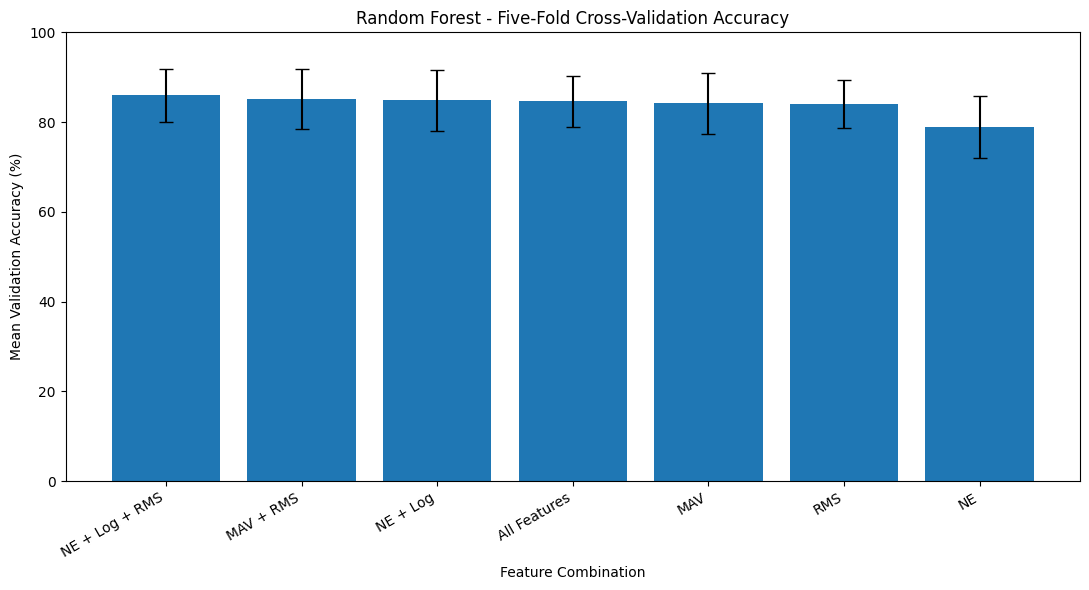

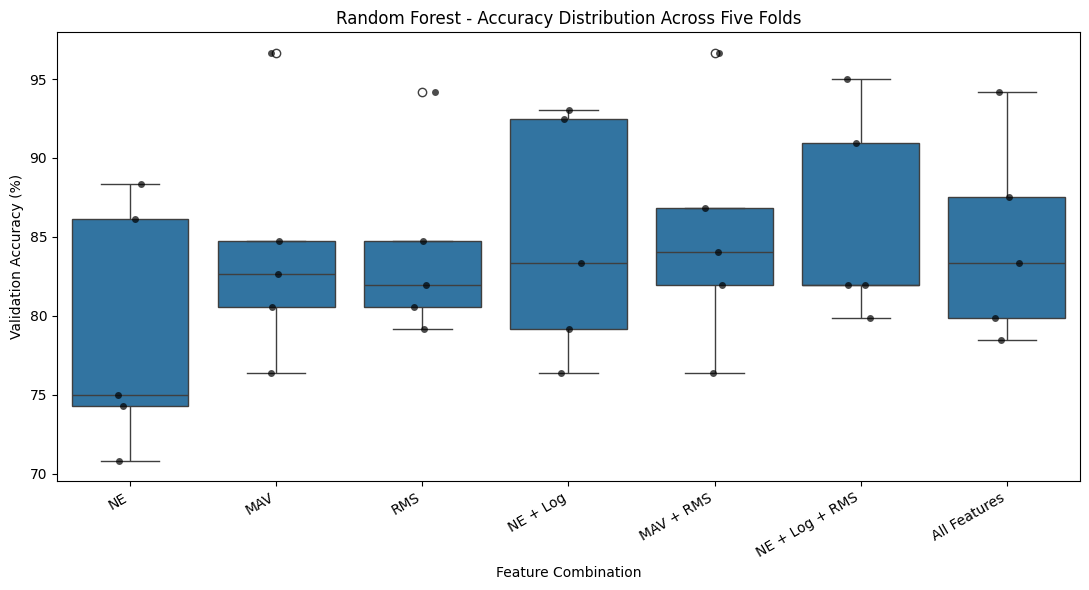

In [ ]:
# ============================================================
# FIVE-FOLD GROUP CROSS-VALIDATION
# RANDOM FOREST - ALL FEATURE COMBINATIONS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score


# ============================================================
# 1. DEFINE FEATURE COMBINATIONS
# ============================================================

feature_sets = {
    "NE": [
        f"NE_ch{i}" for i in range(1, 9)
    ],

    "MAV": [
        f"MAV_ch{i}" for i in range(1, 9)
    ],

    "RMS": [
        f"RMS_ch{i}" for i in range(1, 9)
    ],

    "NE + Log": (
        [f"NE_ch{i}" for i in range(1, 9)]
        + ["Log_Total_Envelope"]
    ),

    "MAV + RMS": (
        [f"MAV_ch{i}" for i in range(1, 9)]
        + [f"RMS_ch{i}" for i in range(1, 9)]
    ),

    "NE + Log + RMS": (
        [f"NE_ch{i}" for i in range(1, 9)]
        + ["Log_Total_Envelope"]
        + [f"RMS_ch{i}" for i in range(1, 9)]
    ),

    "All Features": (
        [f"MAV_ch{i}" for i in range(1, 9)]
        + [f"RMS_ch{i}" for i in range(1, 9)]
        + [f"NE_ch{i}" for i in range(1, 9)]
        + ["Log_Total_Envelope"]
    )
}


# ============================================================
# 2. PREPARE TRAINING DATA
# ============================================================

# Only use the original 29 training subjects
cv_df = df_model.loc[train_indices].copy()

y_cv = cv_df["class"]
groups_cv = cv_df["label"]

# Initialize five-fold grouped cross-validation
gkf = GroupKFold(n_splits=5)

# Store results
cv_results = []
fold_results = []


# ============================================================
# 3. RUN CROSS-VALIDATION
# ============================================================

for model_name, feature_cols in feature_sets.items():

    print("\n" + "=" * 60)
    print(f"MODEL: {model_name}")
    print("=" * 60)

    X_cv = cv_df[feature_cols]

    fold_accuracies = []
    fold_f1_scores = []

    for fold, (train_idx, val_idx) in enumerate(
        gkf.split(X_cv, y_cv, groups=groups_cv),
        start=1
    ):

        # Split data
        X_train_fold = X_cv.iloc[train_idx]
        X_val_fold = X_cv.iloc[val_idx]

        y_train_fold = y_cv.iloc[train_idx]
        y_val_fold = y_cv.iloc[val_idx]

        # Verify no subject overlap
        train_groups = set(groups_cv.iloc[train_idx])
        val_groups = set(groups_cv.iloc[val_idx])

        assert train_groups.isdisjoint(val_groups)

        # Create model
        rf = RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        )

        # Train model
        rf.fit(X_train_fold, y_train_fold)

        # Predict validation set
        y_pred_fold = rf.predict(X_val_fold)

        # Calculate metrics
        accuracy = accuracy_score(
            y_val_fold, y_pred_fold
        )

        f1 = f1_score(
            y_val_fold,
            y_pred_fold,
            average="macro"
        )

        fold_accuracies.append(accuracy)
        fold_f1_scores.append(f1)

        fold_results.append({
            "Model": model_name,
            "Fold": fold,
            "Accuracy": accuracy * 100,
            "F1 Macro": f1 * 100
        })

        print(
            f"Fold {fold}: "
            f"Accuracy = {accuracy*100:.2f}% | "
            f"F1 = {f1*100:.2f}%"
        )

    # Store summary
    cv_results.append({
        "Model": model_name,
        "Features": len(feature_cols),
        "Mean Accuracy (%)": np.mean(fold_accuracies) * 100,
        "Std Accuracy (%)": np.std(fold_accuracies) * 100,
        "Mean F1 (%)": np.mean(fold_f1_scores) * 100
    })


# ============================================================
# 4. CREATE RESULTS DATAFRAMES
# ============================================================

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    "Mean Accuracy (%)",
    ascending=False
)

fold_results_df = pd.DataFrame(fold_results)

print("\n" + "=" * 60)
print("CROSS-VALIDATION MODEL COMPARISON")
print("=" * 60)

display(cv_results_df.round(2))


# ============================================================
# 5. PLOT MEAN CROSS-VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(11, 6))

plt.bar(
    cv_results_df["Model"],
    cv_results_df["Mean Accuracy (%)"],
    yerr=cv_results_df["Std Accuracy (%)"],
    capsize=5
)

plt.title("Random Forest - Five-Fold Cross-Validation Accuracy")
plt.xlabel("Feature Combination")
plt.ylabel("Mean Validation Accuracy (%)")

plt.xticks(rotation=30, ha="right")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()


# ============================================================
# 6. PLOT ACCURACY DISTRIBUTION ACROSS FOLDS
# ============================================================

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=fold_results_df,
    x="Model",
    y="Accuracy"
)

sns.stripplot(
    data=fold_results_df,
    x="Model",
    y="Accuracy",
    color="black",
    alpha=0.7
)

plt.title("Random Forest - Accuracy Distribution Across Five Folds")
plt.xlabel("Feature Combination")
plt.ylabel("Validation Accuracy (%)")

plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

SVM training completed.

SVM PERFORMANCE
Training accuracy: 88.65%
Testing accuracy:  76.79%
Macro F1-score:    0.7737

Classification Report:
              precision    recall  f1-score   support

           1       0.56      0.86      0.68        28
           2       0.85      0.82      0.84        28
           3       0.70      0.68      0.69        28
           4       0.96      0.86      0.91        28
           5       0.95      0.71      0.82        28
           6       0.76      0.68      0.72        28

    accuracy                           0.77       168
   macro avg       0.80      0.77      0.77       168
weighted avg       0.80      0.77      0.77       168



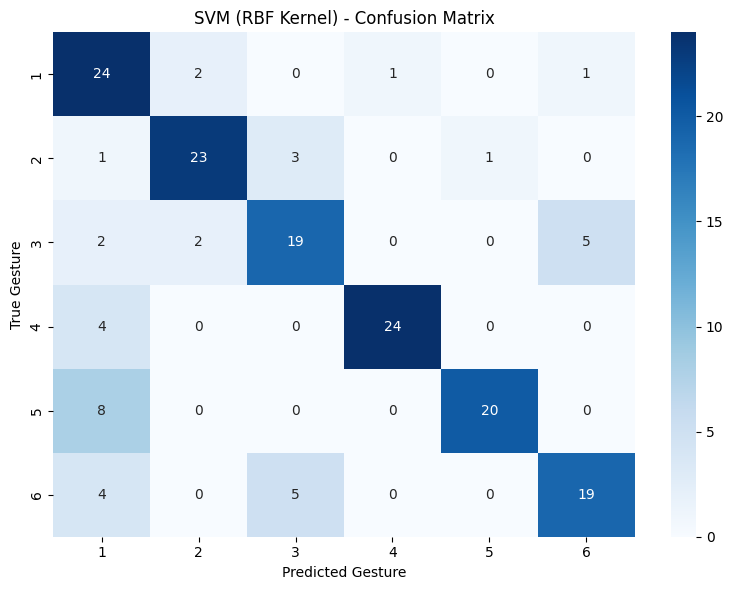

In [ ]:
# ============================================================
# SVM MODEL: NORMALIZED ENVELOPE
# ============================================================

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 1. SELECT FEATURES
# ============================================================

feature_cols = [f"NE_ch{i}" for i in range(1, 9)]

X_train_svm = df_model.loc[X_train.index, feature_cols]
X_test_svm = df_model.loc[X_test.index, feature_cols]


# ============================================================
# 2. CREATE SVM PIPELINE
# ============================================================

svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        random_state=42
    ))
])


# ============================================================
# 3. TRAIN MODEL
# ============================================================

svm_model.fit(X_train_svm, y_train)

print("SVM training completed.")


# ============================================================
# 4. MAKE PREDICTIONS
# ============================================================

y_train_pred_svm = svm_model.predict(X_train_svm)
y_test_pred_svm = svm_model.predict(X_test_svm)


# ============================================================
# 5. EVALUATE MODEL
# ============================================================

train_accuracy_svm = accuracy_score(
    y_train, y_train_pred_svm
)

test_accuracy_svm = accuracy_score(
    y_test, y_test_pred_svm
)

f1_macro_svm = f1_score(
    y_test, y_test_pred_svm, average="macro"
)

print("\n" + "=" * 60)
print("SVM PERFORMANCE")
print("=" * 60)

print(f"Training accuracy: {train_accuracy_svm*100:.2f}%")
print(f"Testing accuracy:  {test_accuracy_svm*100:.2f}%")
print(f"Macro F1-score:    {f1_macro_svm:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_svm))


# ============================================================
# 6. CONFUSION MATRIX
# ============================================================

classes = sorted(y.unique())

cm_svm = confusion_matrix(
    y_test,
    y_test_pred_svm,
    labels=classes
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("SVM (RBF Kernel) - Confusion Matrix")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

SVM - NE + LOG + RMS
Training accuracy: 94.83%
Testing accuracy: 79.17%
Macro F1-score: 0.7959

Classification Report:
              precision    recall  f1-score   support

           1       0.87      0.96      0.92        28
           2       0.80      0.71      0.75        28
           3       0.54      0.71      0.62        28
           4       1.00      0.86      0.92        28
           5       0.85      0.82      0.84        28
           6       0.79      0.68      0.73        28

    accuracy                           0.79       168
   macro avg       0.81      0.79      0.80       168
weighted avg       0.81      0.79      0.80       168



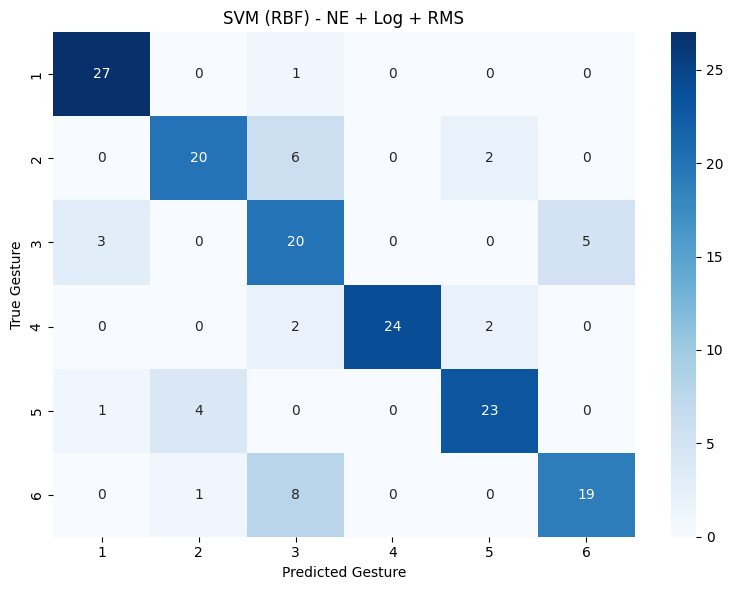

In [ ]:
# ============================================================
# SVM: NORMALIZED ENVELOPE + LOG TOTAL ENVELOPE + RMS
# ============================================================

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 1. SELECT FEATURES
# ============================================================

features_svm_17 = (
    [f"NE_ch{i}" for i in range(1, 9)]
    + ["Log_Total_Envelope"]
    + [f"RMS_ch{i}" for i in range(1, 9)]
)

X_train_svm_17 = df_model.loc[
    train_indices, features_svm_17
]

X_test_svm_17 = df_model.loc[
    test_indices, features_svm_17
]


# ============================================================
# 2. CREATE AND TRAIN SVM
# ============================================================

svm_17 = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

svm_17.fit(X_train_svm_17, y_train)


# ============================================================
# 3. PREDICTIONS
# ============================================================

y_train_pred = svm_17.predict(X_train_svm_17)
y_test_pred = svm_17.predict(X_test_svm_17)


# ============================================================
# 4. EVALUATION
# ============================================================

print("=" * 60)
print("SVM - NE + LOG + RMS")
print("=" * 60)

print(
    f"Training accuracy: "
    f"{accuracy_score(y_train, y_train_pred)*100:.2f}%"
)

print(
    f"Testing accuracy: "
    f"{accuracy_score(y_test, y_test_pred)*100:.2f}%"
)

print(
    f"Macro F1-score: "
    f"{f1_score(y_test, y_test_pred, average='macro'):.4f}"
)

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))


# ============================================================
# 5. CONFUSION MATRIX
# ============================================================

classes = sorted(y.unique())

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=classes
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("SVM (RBF) - NE + Log + RMS")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

Model-training subjects: 23
Validation subjects: 6
Final test subjects: 7


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           102 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 918 (3.59 KB)

 Trainable params: 918 (3.59 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.3043 - loss: 1.7354 - val_accuracy: 0.4931 - val_loss: 1.4999
Epoch 2/200
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4149 - loss: 1.5483 - val_accuracy: 0.6250 - val_loss: 1.3346
Epoch 3/200
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4583 - loss: 1.4480 - val_accuracy: 0.7222 - val_loss: 1.2067
Epoch 4/200
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5670 - loss: 1.3045 - val_accuracy: 0.7708 - val_loss: 1.0773
Epoch 5/200
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5652 - loss: 1.2511 - val_accuracy: 0.7986 - val_loss: 0.9618
Epoch 6/200
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5978 - loss: 1.1877 - val_accuracy: 0.8333 - val_loss: 0.8621
Epoch 7/200
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6014 - loss: 1.1327 - val_accuracy: 0.8333 - val_loss: 0.7847
Epoch 8/200
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6286 - loss: 1.0292 - val_accuracy: 0.8403 - 

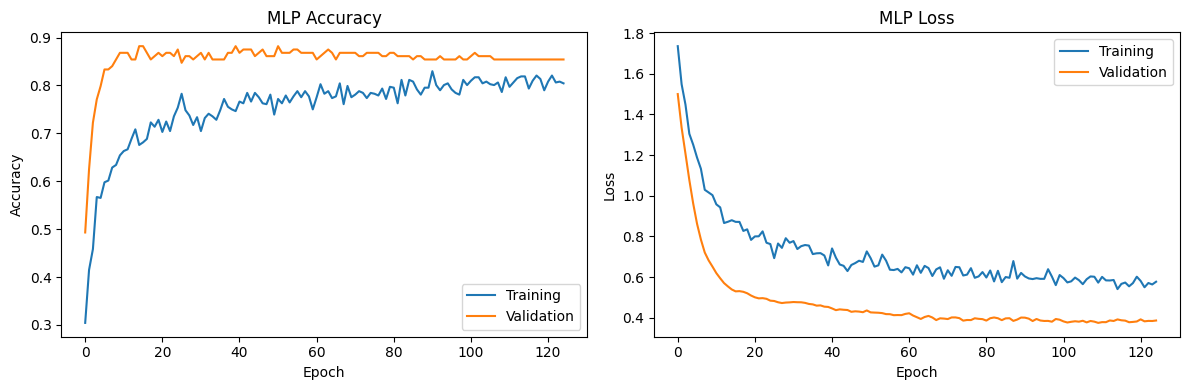

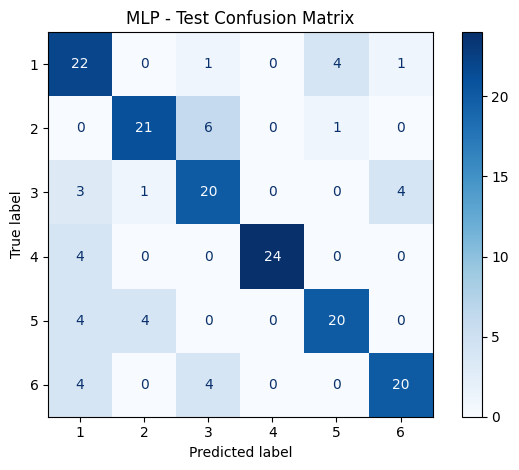

In [ ]:
# ============================================================
# 9. DEEP LEARNING MODEL - MULTILAYER PERCEPTRON
# ============================================================

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.regularizers import l2

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# ------------------------------------------------------------
# 9.1 Create a subject-based validation split
# ------------------------------------------------------------

# Use only the training subjects for model development.
train_groups = groups.iloc[train_idx].reset_index(drop=True)

X_train_reset = X_train.reset_index(drop=True)
y_train_reset = y_train.reset_index(drop=True)

# Keep complete subjects together in the validation split.
val_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

fit_idx, val_idx = next(
    val_splitter.split(
        X_train_reset,
        y_train_reset,
        groups=train_groups
    )
)

X_fit = X_train_reset.iloc[fit_idx]
X_val = X_train_reset.iloc[val_idx]

y_fit = y_train_reset.iloc[fit_idx]
y_val = y_train_reset.iloc[val_idx]

# Verify that subjects do not overlap.
fit_subjects = set(train_groups.iloc[fit_idx])
val_subjects = set(train_groups.iloc[val_idx])

assert fit_subjects.isdisjoint(val_subjects)

print("Model-training subjects:", len(fit_subjects))
print("Validation subjects:", len(val_subjects))
print("Final test subjects:", len(test_subjects))

# ------------------------------------------------------------
# 9.2 Standardize features
# ------------------------------------------------------------

# Fit the scaler only on the model-training data.
scaler = StandardScaler()

X_fit_scaled = scaler.fit_transform(X_fit)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# ------------------------------------------------------------
# 9.3 Encode gesture labels
# ------------------------------------------------------------

# Map gesture labels to consecutive integers starting at zero.
label_encoder = LabelEncoder()

y_fit_encoded = label_encoder.fit_transform(y_fit)
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)

n_classes = len(label_encoder.classes_)
n_features = X_fit_scaled.shape[1]

# ------------------------------------------------------------
# 9.4 Define the neural network
# ------------------------------------------------------------

model = Sequential([
    Input(shape=(n_features,)),

    Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),
    Dropout(0.30),

    Dense(
        16,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),
    Dropout(0.20),

    Dense(n_classes, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# ------------------------------------------------------------
# 9.5 Train with early stopping
# ------------------------------------------------------------

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

history = model.fit(
    X_fit_scaled,
    y_fit_encoded,
    validation_data=(X_val_scaled, y_val_encoded),
    epochs=200,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)

# ------------------------------------------------------------
# 9.6 Evaluate on the independent test subjects
# ------------------------------------------------------------

train_pred = np.argmax(
    model.predict(X_fit_scaled, verbose=0),
    axis=1
)

test_pred = np.argmax(
    model.predict(X_test_scaled, verbose=0),
    axis=1
)

train_accuracy = accuracy_score(y_fit_encoded, train_pred)
test_accuracy = accuracy_score(y_test_encoded, test_pred)

print(f"\nTraining accuracy: {train_accuracy:.4f}")
print(f"Test accuracy:     {test_accuracy:.4f}")

print("\nClassification report:")
print(classification_report(
    y_test_encoded,
    test_pred,
    labels=np.arange(n_classes),
    target_names=[
        str(c) for c in label_encoder.classes_
    ],
    zero_division=0
))

# ------------------------------------------------------------
# 9.7 Plot learning curves
# ------------------------------------------------------------

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MLP Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP Loss")
plt.legend()

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9.8 Plot confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test_encoded,
    test_pred,
    labels=np.arange(n_classes)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot(cmap="Blues", values_format="d")
plt.title("MLP - Test Confusion Matrix")
plt.tight_layout()
plt.show()

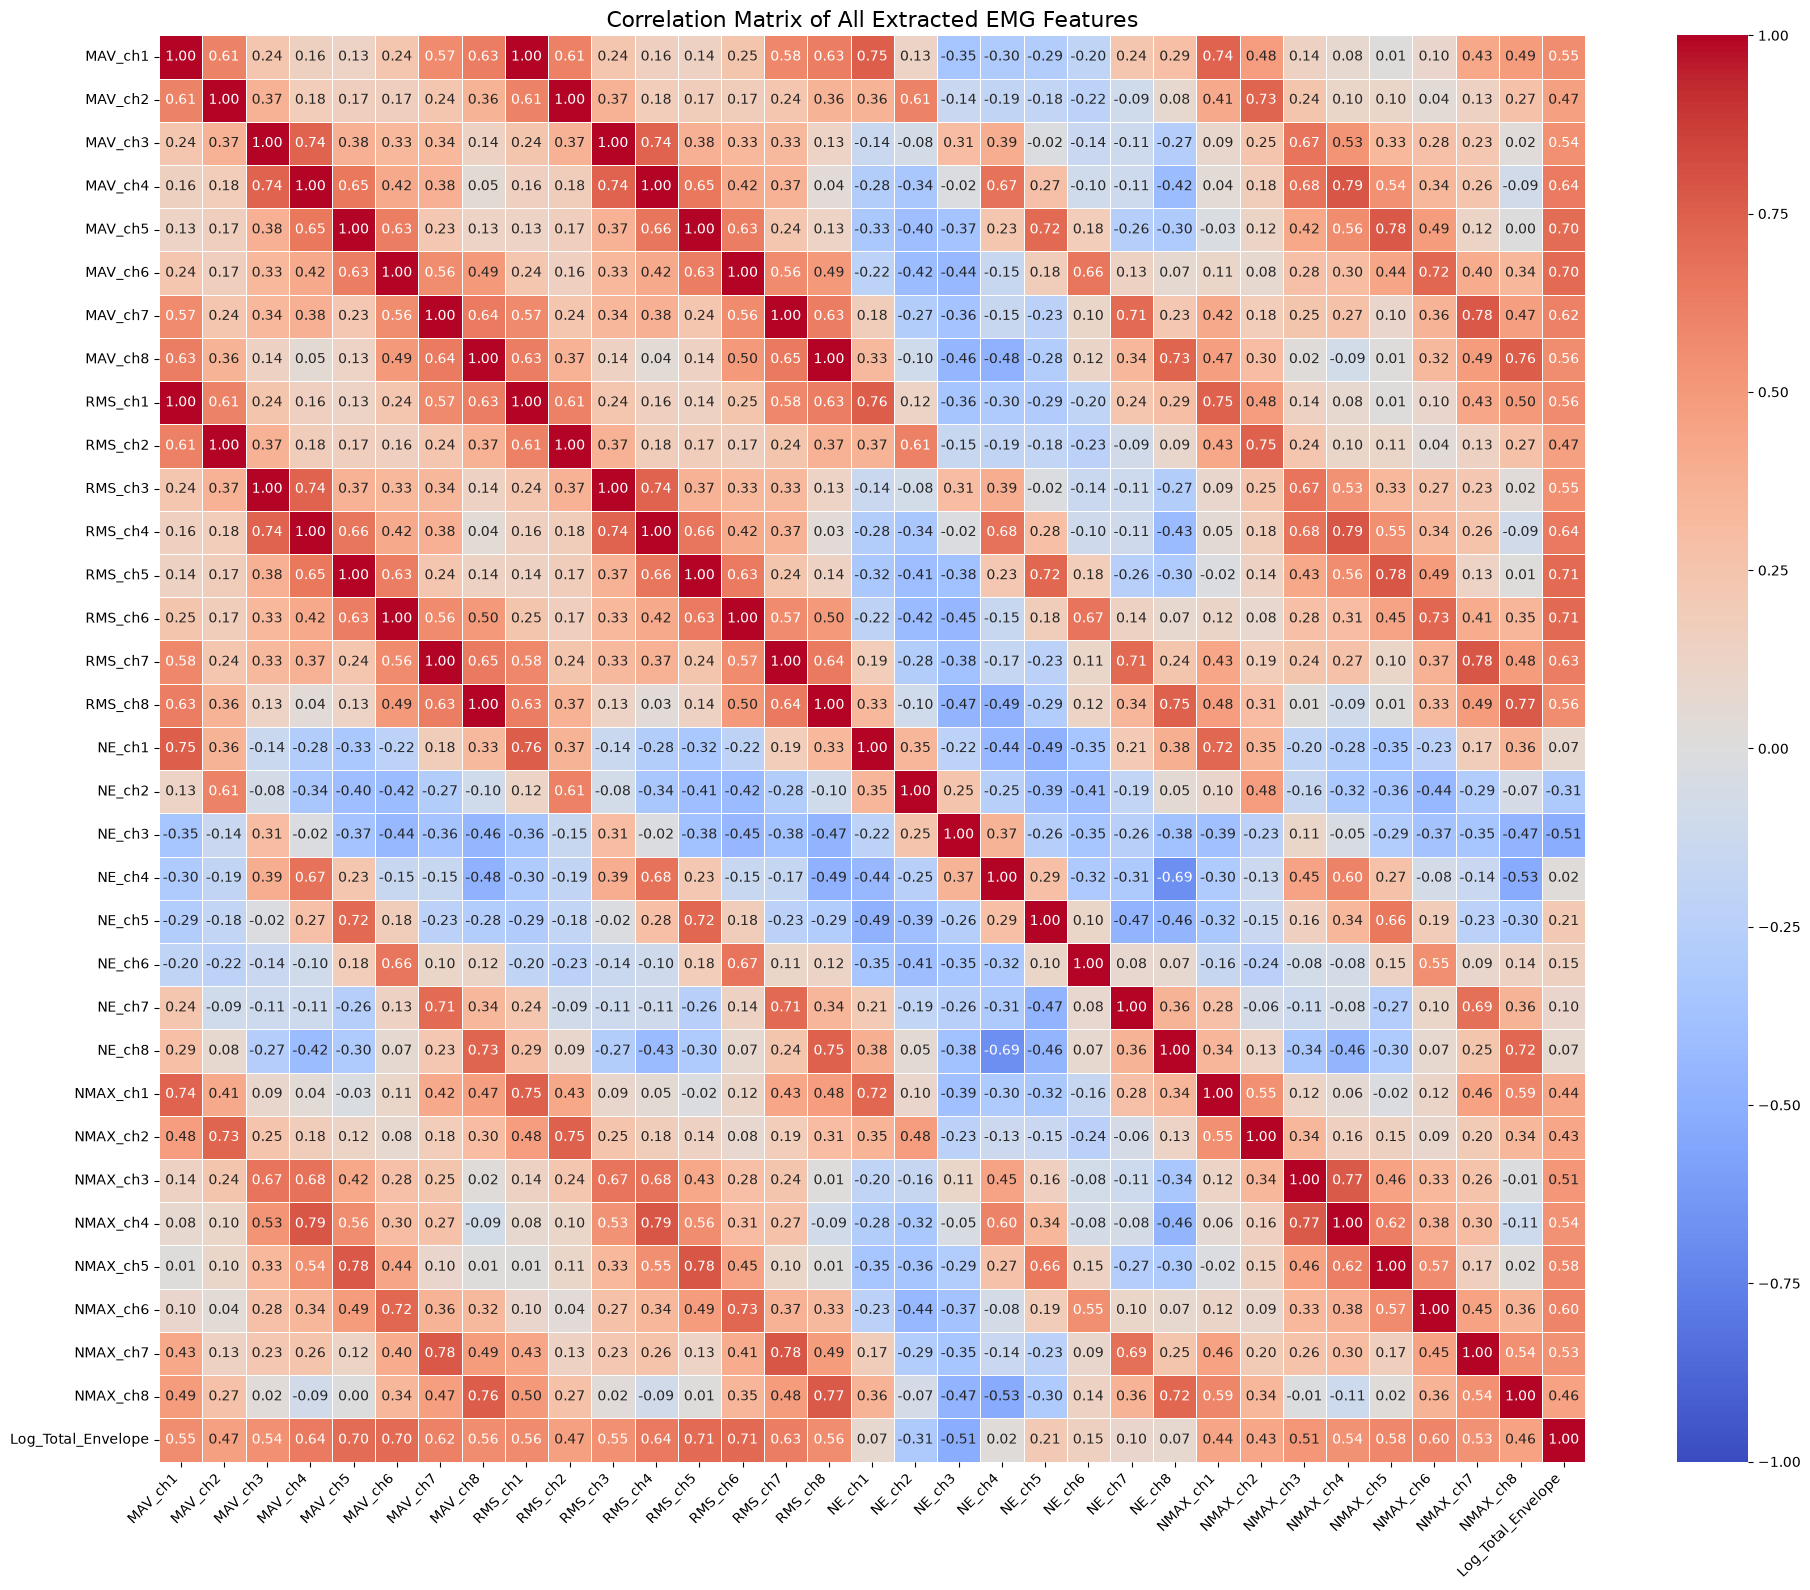

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select all extracted numerical features
feature_cols = (
    [f"MAV_ch{i}" for i in range(1, 9)]
    + [f"RMS_ch{i}" for i in range(1, 9)]
    + [f"NE_ch{i}" for i in range(1, 9)]
    + [f"NMAX_ch{i}" for i in range(1, 9)]
    + ["Log_Total_Envelope"]
)

# Calculate the Pearson correlation matrix
correlation_matrix = df_model[feature_cols].corr(method="pearson")

# Visualize the correlation matrix
plt.figure(figsize=(20, 16))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Correlation Matrix of All Extracted EMG Features", fontsize=16)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

DATASET OVERVIEW
Total samples: 4,237,907
Total subjects: 36
Gesture classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]

Total recording sessions: 72
Total gesture blocks: 1812

Extracted gesture blocks: 1812

FINAL FEATURES DATAFRAME
Shape: (864, 44)
Number of features: 40
Number of gesture blocks: 864
Classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


,gesture_block,label,series,class,MAV_ch1,MAV_ch2,MAV_ch3,MAV_ch4,MAV_ch5,MAV_ch6,...,CAR_ch7,CAR_ch8,NMAX_ch1,NMAX_ch2,NMAX_ch3,NMAX_ch4,NMAX_ch5,NMAX_ch6,NMAX_ch7,NMAX_ch8
1,2,1,1,1,0.000012,0.000019,0.000021,0.000015,0.000012,0.000011,...,0.092539,0.097195,0.092468,0.123766,0.167107,0.097560,0.063458,0.062441,0.082986,0.081992
3,4,1,1,2,0.000189,0.000105,0.000171,0.000133,0.000128,0.000168,...,0.160588,0.108157,2.113459,0.735396,1.566345,1.049156,0.644400,1.026053,2.538136,1.478215
5,6,1,1,3,0.000124,0.000137,0.000052,0.000049,0.000116,0.000071,...,0.072196,0.158889,1.167375,1.182072,0.450270,0.387802,0.800014,0.533324,0.431707,0.937591
7,8,1,1,4,0.000038,0.000056,0.000080,0.000172,0.000285,0.000208,...,0.086044,0.065793,0.827440,1.448729,2.018061,2.408060,2.777335,3.002969,0.653224,0.635617
9,10,1,1,5,0.000047,0.000108,0.000174,0.000240,0.000248,0.000160,...,0.072778,0.046383,0.452413,0.807021,1.844367,1.887040,1.595248,0.957422,0.777211,0.459895


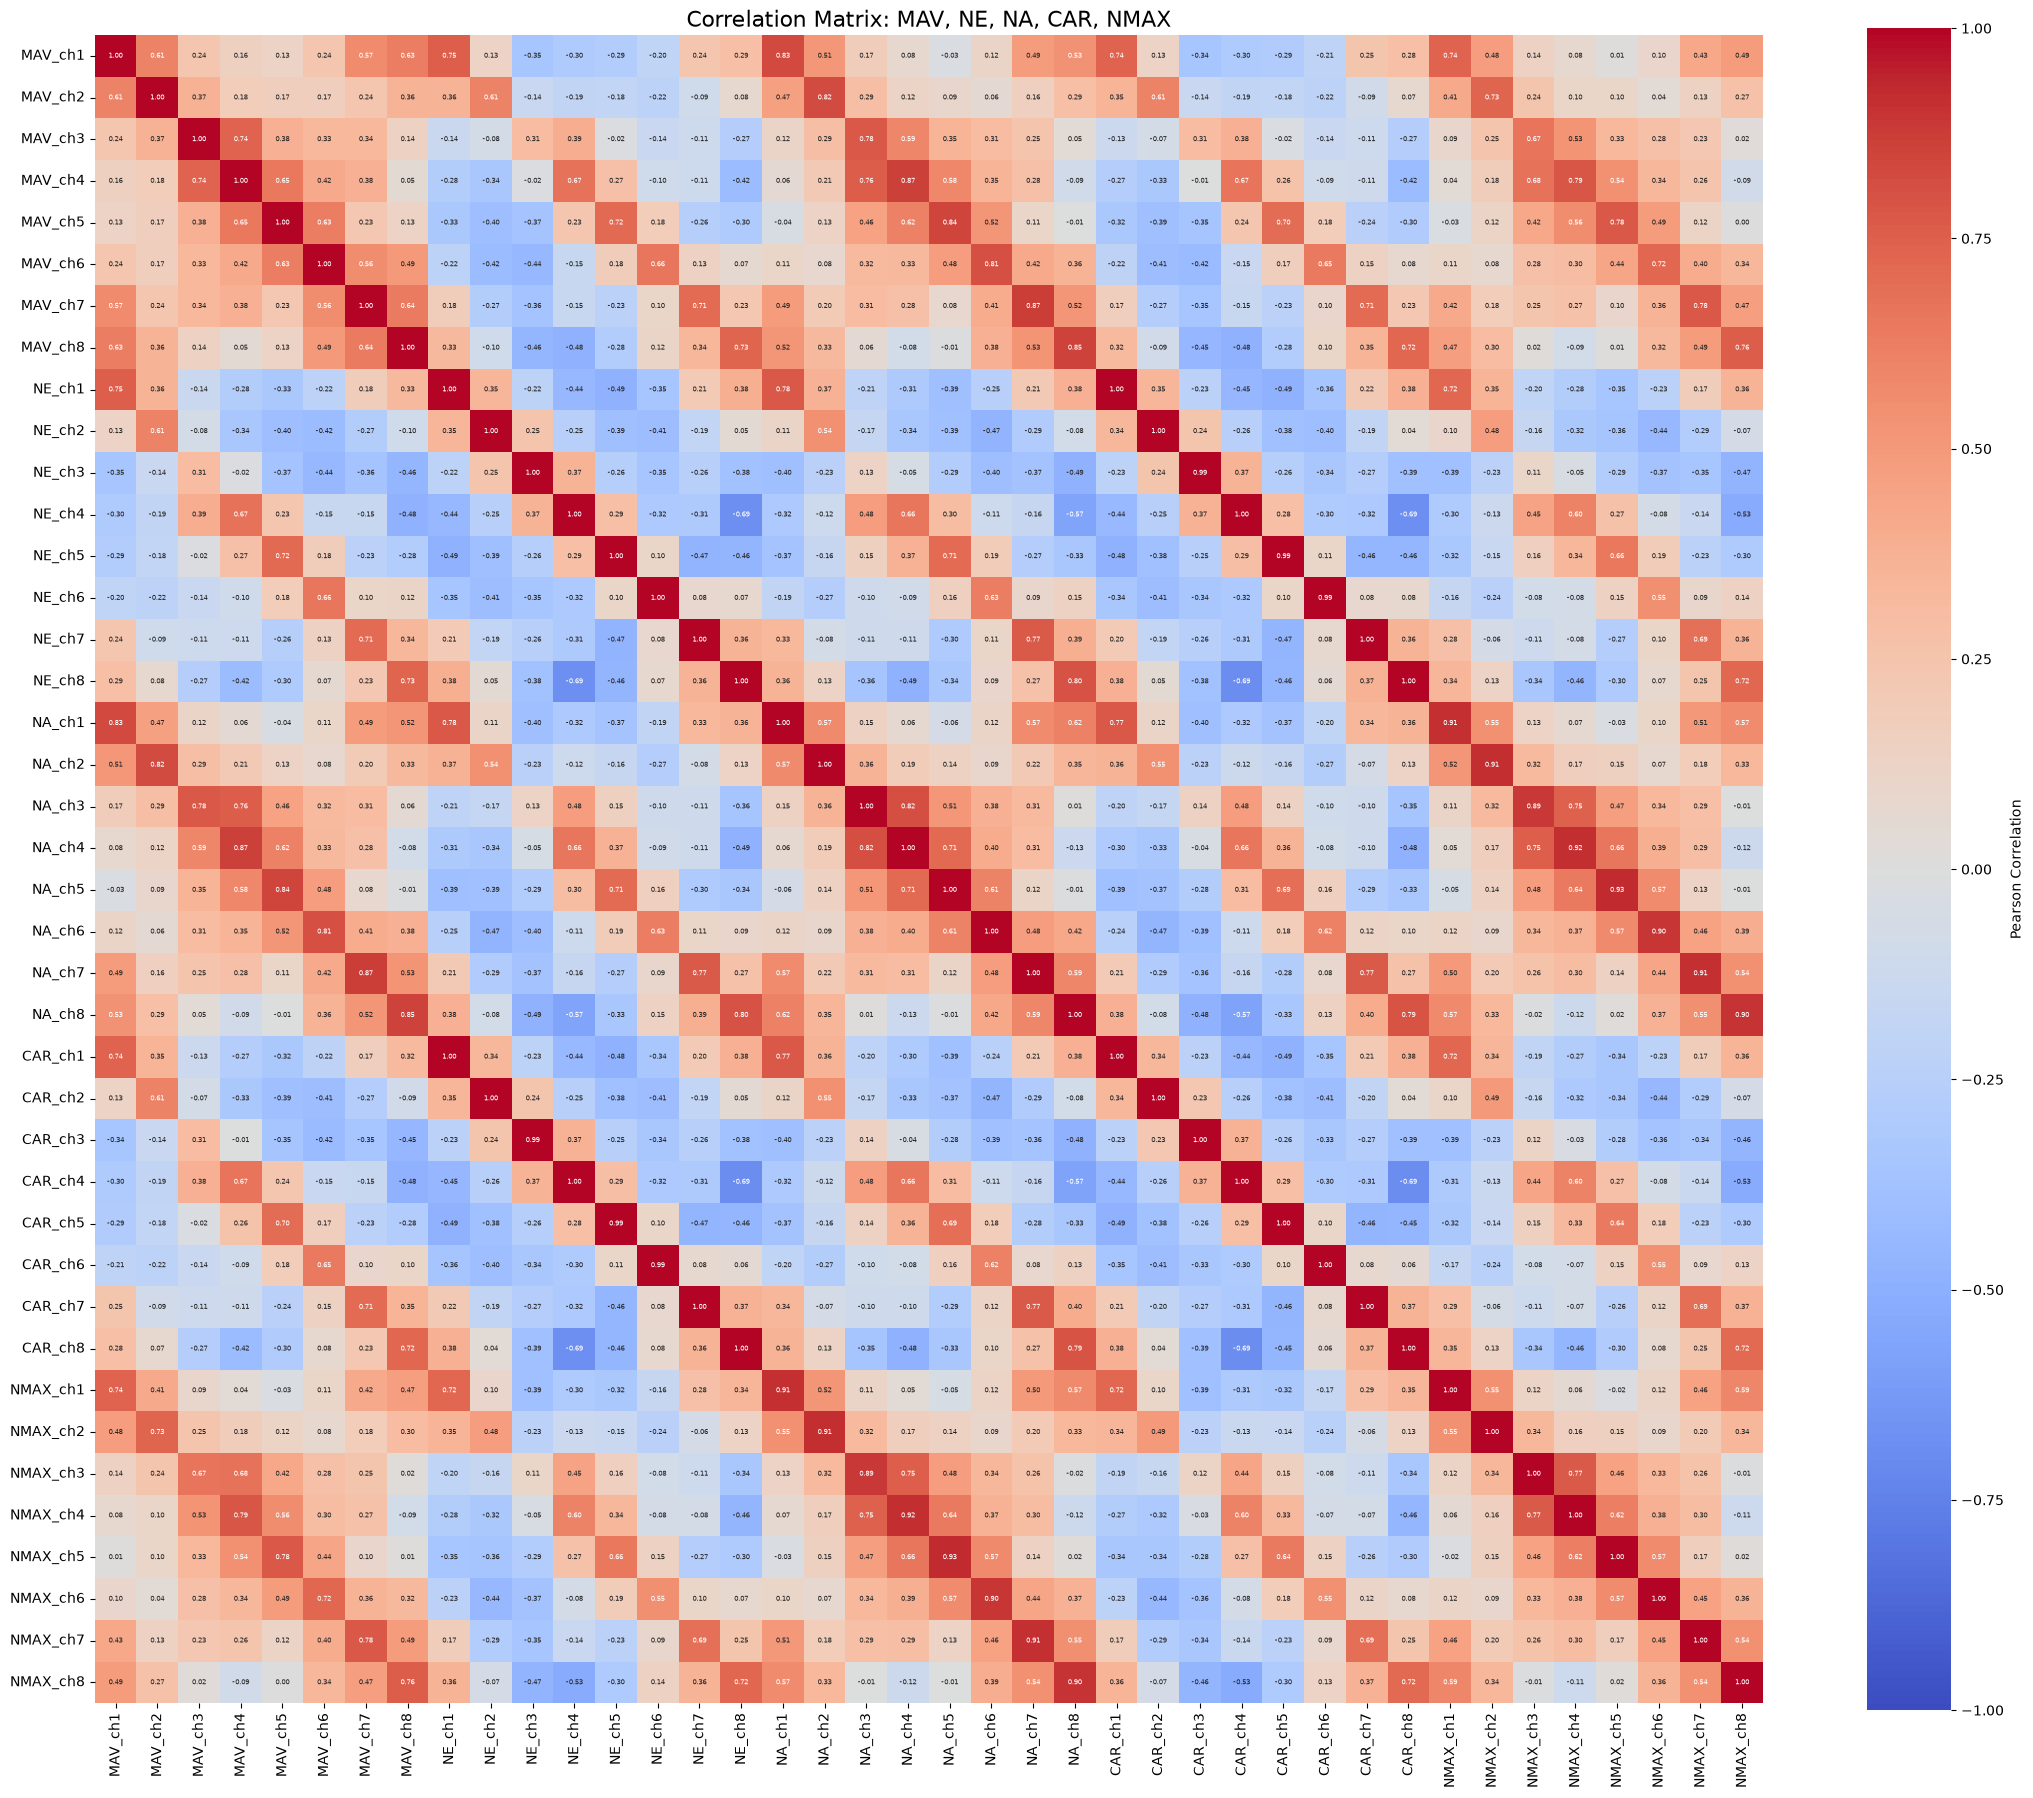

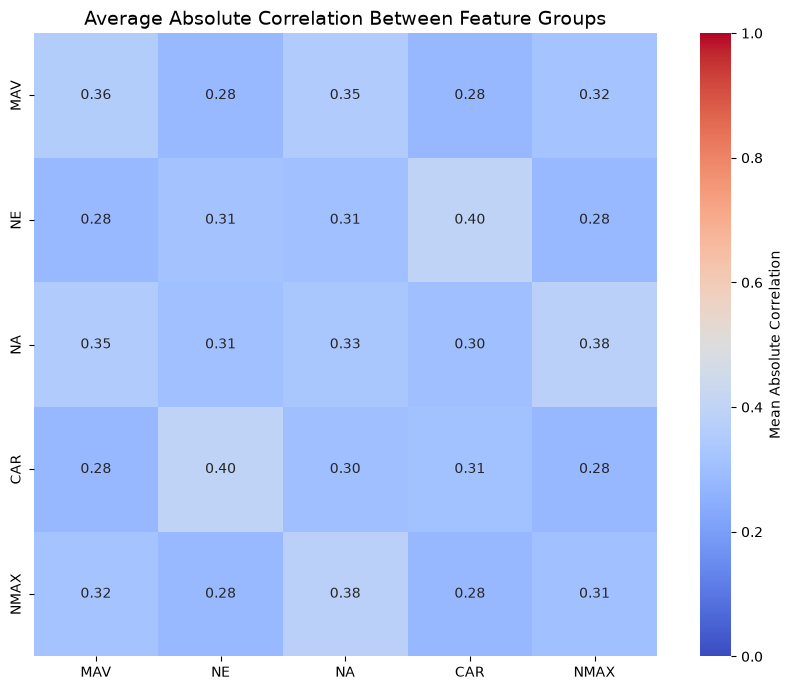

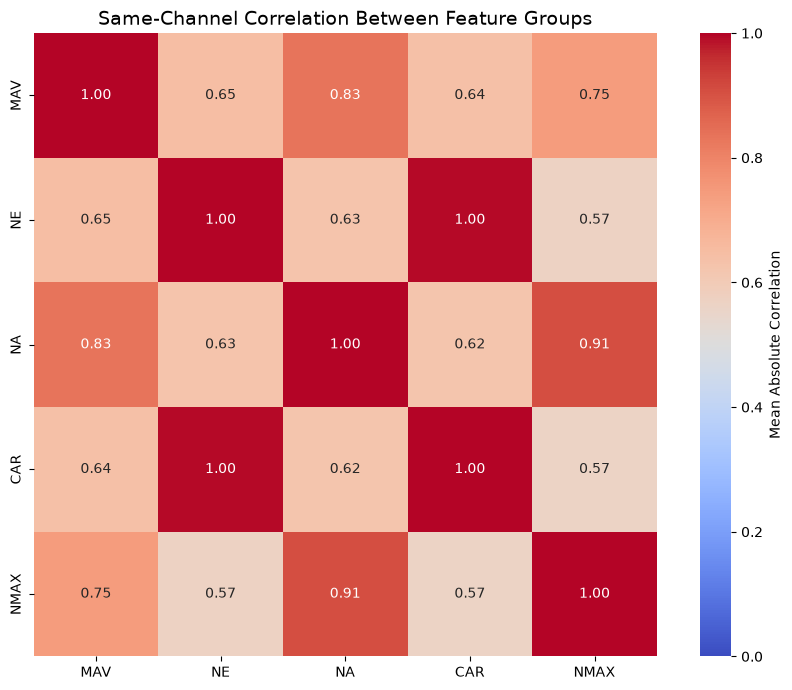


Average absolute correlation between all channels:


,MAV,NE,NA,CAR,NMAX
MAV,0.362,0.285,0.352,0.281,0.317
NE,0.285,0.313,0.307,0.397,0.282
NA,0.352,0.307,0.333,0.304,0.381
CAR,0.281,0.397,0.304,0.310,0.280
NMAX,0.317,0.282,0.381,0.280,0.306



Average absolute correlation between matching channels:


,MAV,NE,NA,CAR,NMAX
MAV,1.000,0.646,0.833,0.638,0.745
NE,0.646,1.000,0.626,0.995,0.567
NA,0.833,0.626,1.000,0.623,0.908
CAR,0.638,0.995,0.623,1.000,0.566
NMAX,0.745,0.567,0.908,0.566,1.000


In [13]:
# ============================================================
# EMG FEATURE EXTRACTION AND CORRELATION ANALYSIS
# Features: MAV, NE, NA, CAR, NMAX
# ============================================================

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.signal import butter, filtfilt


# ============================================================
# 2. LOAD DATASET
# ============================================================

data = pd.read_csv("Project_Data_EE4C12_S&S_EMG.csv")

channels = [f"channel{i}" for i in range(1, 9)]

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print(f"Total samples: {len(data):,}")
print(f"Total subjects: {data['label'].nunique()}")
print(f"Gesture classes: {sorted(data['class'].unique())}")


# ============================================================
# 3. IDENTIFY RECORDING SESSIONS
# ============================================================

# A new session starts when time resets within a subject
data["new_series"] = (
    data.groupby("label")["time"]
        .diff()
        .fillna(1)
        <= 0
)

# First row of each subject starts a new session
data["new_series"] = (
    data["new_series"]
    | data.groupby("label").cumcount().eq(0)
)

# Assign session numbers
data["series"] = (
    data.groupby("label")["new_series"]
        .cumsum()
        .astype(int)
)

data.drop(columns="new_series", inplace=True)

print("\nTotal recording sessions:",
      data.groupby(["label", "series"]).ngroups)


# ============================================================
# 4. IDENTIFY GESTURE BLOCKS
# ============================================================

# New block when class, session or subject changes
data["new_gesture"] = (
    data["class"].ne(data["class"].shift())
    | data["series"].ne(data["series"].shift())
    | data["label"].ne(data["label"].shift())
)

data["gesture_block"] = data["new_gesture"].cumsum()

data.drop(columns="new_gesture", inplace=True)

print("Total gesture blocks:",
      data["gesture_block"].nunique())


# ============================================================
# 5. FILTER PARAMETERS
# ============================================================

fs = 1000
cutoff = 3
order = 4

# Fourth-order Butterworth low-pass filter
b, a = butter(
    order,
    cutoff / (fs / 2),
    btype="low"
)

padlen = 3 * max(len(a), len(b))


# ============================================================
# 6. EXTRACT MAV, RMS, NE AND MAX
# ============================================================

feature_rows = []

for block_id, group in data.groupby(
    "gesture_block", sort=False
):

    stroke = group[channels].to_numpy(dtype=float)

    # Skip blocks too short for filtering
    if len(stroke) <= padlen:
        continue

    # Rectify EMG
    rectified = np.abs(stroke)

    # Extract envelope
    envelope = filtfilt(
        b, a, rectified, axis=0
    )

    # Mean Absolute Value (MAV)
    mav = np.mean(envelope, axis=0)

    # Root Mean Square (RMS)
    rms = np.sqrt(np.mean(stroke**2, axis=0))

    # Normalized Envelope (NE)
    total_envelope = np.sum(mav)

    ne = mav / (total_envelope + 1e-10)

    # Maximum Envelope Amplitude (MAX)
    max_values = np.max(envelope, axis=0)

    # Store features
    features = {
        "gesture_block": block_id,
        "label": group["label"].iloc[0],
        "series": group["series"].iloc[0],
        "class": group["class"].iloc[0]
    }

    for ch in range(8):

        features[f"MAV_ch{ch+1}"] = mav[ch]
        features[f"RMS_ch{ch+1}"] = rms[ch]
        features[f"NE_ch{ch+1}"] = ne[ch]
        features[f"MAX_ch{ch+1}"] = max_values[ch]

    feature_rows.append(features)


features_df = pd.DataFrame(feature_rows)

print("\nExtracted gesture blocks:", len(features_df))


# ============================================================
# 7. NORMALIZED AMPLITUDE (NA)
# ============================================================

# Calculate class-balanced reference MAV for each
# subject, session and channel

mav_cols = [f"MAV_ch{i}" for i in range(1, 9)]

# Step 1: Mean MAV per subject, session and class
mav_class_means = (
    features_df
    .groupby(["label", "series", "class"])[mav_cols]
    .mean()
    .reset_index()
)

# Step 2: Equal weighting across gesture classes
mav_balanced_means = (
    mav_class_means
    .groupby(["label", "series"])[mav_cols]
    .mean()
)

# Step 3: Match reference to each gesture block
reference = features_df.set_index(
    ["label", "series"]
).index

mav_reference = (
    mav_balanced_means
    .reindex(reference)
    .to_numpy()
)

# Step 4: Calculate NA
for i, col in enumerate(mav_cols):

    features_df[f"NA_ch{i+1}"] = (
        features_df[col] /
        (mav_reference[:, i] + 1e-10)
    )


# ============================================================
# 8. CHANNEL ACTIVATION RATIO (CAR)
# ============================================================

# CAR = RMS of channel / sum of RMS across channels

rms_cols = [f"RMS_ch{i}" for i in range(1, 9)]

rms_values = features_df[rms_cols].to_numpy(
    dtype=float
)

total_rms = np.sum(
    rms_values,
    axis=1,
    keepdims=True
)

car_values = np.divide(
    rms_values,
    total_rms,
    out=np.full_like(rms_values, np.nan),
    where=total_rms > 1e-12
)

for ch in range(8):

    features_df[f"CAR_ch{ch+1}"] = car_values[:, ch]


# ============================================================
# 9. NORMALIZED MAXIMUM AMPLITUDE (NMAX)
# ============================================================

max_cols = [f"MAX_ch{i}" for i in range(1, 9)]

# Step 1: Mean MAX per subject, session and class
max_class_means = (
    features_df
    .groupby(["label", "series", "class"])[max_cols]
    .mean()
    .reset_index()
)

# Step 2: Equal weighting across gesture classes
max_balanced_means = (
    max_class_means
    .groupby(["label", "series"])[max_cols]
    .mean()
)

# Step 3: Match reference values
max_reference = (
    max_balanced_means
    .reindex(reference)
    .to_numpy()
)

# Step 4: Calculate NMAX
for i, col in enumerate(max_cols):

    features_df[f"NMAX_ch{i+1}"] = (
        features_df[col] /
        (max_reference[:, i] + 1e-10)
    )


# ============================================================
# 10. CREATE NEW FEATURES DATAFRAME
# ============================================================

# Exclude classes 0 and 7
df_filtered = features_df[
    ~features_df["class"].isin([0, 7])
].copy()

# Select the five feature groups
feature_groups = ["MAV", "NE", "NA", "CAR", "NMAX"]

feature_columns = [
    f"{feature}_ch{i}"
    for feature in feature_groups
    for i in range(1, 9)
]

# Create final DataFrame
df_features_new = df_filtered[
    ["gesture_block", "label", "series", "class"]
    + feature_columns
].copy()

print("\n" + "=" * 60)
print("FINAL FEATURES DATAFRAME")
print("=" * 60)

print("Shape:", df_features_new.shape)
print("Number of features:", len(feature_columns))
print("Number of gesture blocks:", len(df_features_new))
print("Classes:", sorted(df_features_new["class"].unique()))

display(df_features_new.head())

# Check for missing or infinite values
assert np.isfinite(
    df_features_new[feature_columns].to_numpy()
).all(), "Missing or infinite feature values detected."


# ============================================================
# 11. FULL CORRELATION MATRIX (40 FEATURES)
# ============================================================

correlation_matrix = (
    df_features_new[feature_columns]
    .corr(method="pearson")
)

plt.figure(figsize=(22, 18))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    annot_kws={"size": 5},
    cbar_kws={"label": "Pearson Correlation"}
)

plt.title(
    "Correlation Matrix: MAV, NE, NA, CAR, NMAX",
    fontsize=16
)

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


# ============================================================
# 12. CORRELATION BETWEEN FEATURE GROUPS
# ============================================================

# Calculate average absolute correlation
# between each pair of feature groups

group_corr = pd.DataFrame(
    index=feature_groups,
    columns=feature_groups,
    dtype=float
)

for group1 in feature_groups:

    for group2 in feature_groups:

        cols1 = [
            f"{group1}_ch{i}"
            for i in range(1, 9)
        ]

        cols2 = [
            f"{group2}_ch{i}"
            for i in range(1, 9)
        ]

        values = (
            correlation_matrix
            .loc[cols1, cols2]
            .abs()
            .to_numpy()
        )

        if group1 == group2:

            # Exclude diagonal self-correlations
            mask = ~np.eye(8, dtype=bool)

            group_corr.loc[group1, group2] = (
                np.nanmean(values[mask])
            )

        else:

            group_corr.loc[group1, group2] = (
                np.nanmean(values)
            )


plt.figure(figsize=(9, 7))

sns.heatmap(
    group_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=0,
    vmax=1,
    square=True,
    cbar_kws={"label": "Mean Absolute Correlation"}
)

plt.title(
    "Average Absolute Correlation Between Feature Groups",
    fontsize=14
)

plt.tight_layout()
plt.show()


# ============================================================
# 13. SAME-CHANNEL CORRELATION BETWEEN FEATURE GROUPS
# ============================================================

# Compare corresponding channels only:
# e.g. MAV_ch1 vs NA_ch1

same_channel_corr = pd.DataFrame(
    index=feature_groups,
    columns=feature_groups,
    dtype=float
)

for group1 in feature_groups:

    for group2 in feature_groups:

        correlations = []

        for ch in range(1, 9):

            col1 = f"{group1}_ch{ch}"
            col2 = f"{group2}_ch{ch}"

            correlations.append(
                abs(correlation_matrix.loc[col1, col2])
            )

        same_channel_corr.loc[group1, group2] = (
            np.nanmean(correlations)
        )


plt.figure(figsize=(9, 7))

sns.heatmap(
    same_channel_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=0,
    vmax=1,
    square=True,
    cbar_kws={"label": "Mean Absolute Correlation"}
)

plt.title(
    "Same-Channel Correlation Between Feature Groups",
    fontsize=14
)

plt.tight_layout()
plt.show()


# ============================================================
# 14. DISPLAY CORRELATION TABLES
# ============================================================

print("\nAverage absolute correlation between all channels:")
display(group_corr.round(3))

print("\nAverage absolute correlation between matching channels:")
display(same_channel_corr.round(3))
